In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn

# ================================================
# PROJECT 1: BREAST CANCER BINARY CLASSIFICATION
(NEURAL NETWORK FROM SCRATCH USING NUMPY)
# ================================================

Dataset Shape: (569, 30)
Target Shape: (569, 1)
Features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Classes: ['malignant' 'benign']

Class Distribution:
1    357
0    212
Name: count, dtype: int64

Training: (398, 30)
Validation: (85, 30)
Testing: (86, 30)
Epoch 50/500 | Train Loss: 0.1129 | Val Loss: 0.1139 | Train Accuracy: 0.9698 | Val Accuracy: 0.9529
Epoch 100/500 | Train Loss: 0.0779 | Val Loss: 0.0723 | Train Accuracy: 0.9849 | Val Accuracy: 0.9765
Epoch 150/500 | Train Loss:

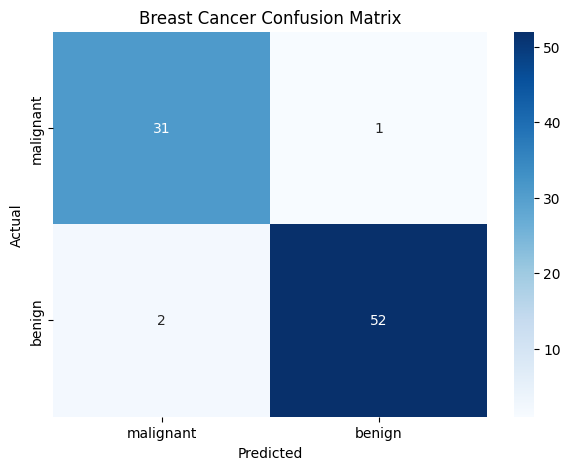

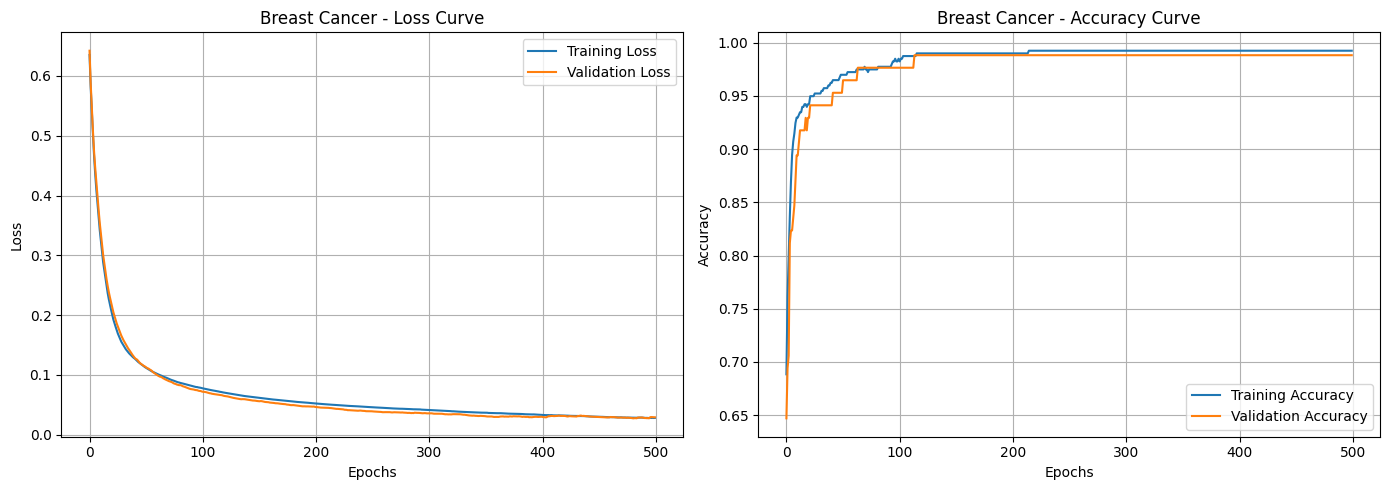


New Sample Prediction:
malignant

BREAST CANCER PROJECT COMPLETED!


In [2]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)

data = load_breast_cancer()

X = data.data
y = data.target.reshape(-1, 1)

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("Features:", data.feature_names)
print("Classes:", data.target_names)

print("\nClass Distribution:")
print(pd.Series(y.ravel()).value_counts())


# Training: 70%, Validation: 15%, Testing: 15%

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Feature scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)



# BUILD NEURAL NETWORK FROM SCRATCH


class NeuralNetwork:

    def __init__(
        self,
        input_size,
        hidden1=16,
        hidden2=8,
        output_size=1,
        learning_rate=0.01,
        epochs=500,
        batch_size=32,
        dropout_rate=0.20,
        l2_lambda=0.001
    ):

        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.dropout_rate = dropout_rate
        self.l2_lambda = l2_lambda

        # Initialize weights and biases

        self.W1 = np.random.randn(input_size, hidden1) * np.sqrt(2 / input_size)
        self.b1 = np.zeros((1, hidden1))

        self.W2 = np.random.randn(hidden1, hidden2) * np.sqrt(2 / hidden1)
        self.b2 = np.zeros((1, hidden2))

        self.W3 = np.random.randn(hidden2, output_size) * np.sqrt(2 / hidden2)
        self.b3 = np.zeros((1, output_size))

        # Store training history

        self.train_losses = []
        self.val_losses = []
        self.train_accuracies = []
        self.val_accuracies = []


    # Activation functions

    def relu(self, z):
        return np.maximum(0, z)

    def relu_derivative(self, z):
        return (z > 0).astype(float)

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))


    # Forward propagation

    def forward(self, X, training=False):

        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.relu(self.Z1)

        # Dropout layer 1

        if training and self.dropout_rate > 0:

            self.D1 = (
                np.random.rand(*self.A1.shape) >= self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.A1 *= self.D1

        else:
            self.D1 = np.ones_like(self.A1)

        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self.relu(self.Z2)

        # Dropout layer 2

        if training and self.dropout_rate > 0:

            self.D2 = (
                np.random.rand(*self.A2.shape) >= self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.A2 *= self.D2

        else:
            self.D2 = np.ones_like(self.A2)

        self.Z3 = self.A2 @ self.W3 + self.b3

        self.A3 = self.sigmoid(self.Z3)

        return self.A3


    # Binary Cross-Entropy + L2 Regularization

    def calculate_loss(self, y_true, y_pred):

        eps = 1e-9
        m = len(y_true)

        bce = -np.mean(
            y_true * np.log(y_pred + eps) +
            (1 - y_true) * np.log(1 - y_pred + eps)
        )

        l2 = (self.l2_lambda / (2 * m)) * (
            np.sum(self.W1 ** 2) +
            np.sum(self.W2 ** 2) +
            np.sum(self.W3 ** 2)
        )

        return bce + l2


    # Backpropagation

    def backward(self, X, y):

        m = X.shape[0]

        # Output layer

        dZ3 = self.A3 - y

        dW3 = self.A2.T @ dZ3 / m
        db3 = np.sum(dZ3, axis=0, keepdims=True) / m

        # Hidden layer 2

        dA2 = dZ3 @ self.W3.T
        dA2 *= self.D2

        dZ2 = dA2 * self.relu_derivative(self.Z2)

        dW2 = self.A1.T @ dZ2 / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        # Hidden layer 1

        dA1 = dZ2 @ self.W2.T
        dA1 *= self.D1

        dZ1 = dA1 * self.relu_derivative(self.Z1)

        dW1 = X.T @ dZ1 / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        # L2 regularization gradients

        dW1 += self.l2_lambda * self.W1 / m
        dW2 += self.l2_lambda * self.W2 / m
        dW3 += self.l2_lambda * self.W3 / m

        return dW1, db1, dW2, db2, dW3, db3


    # Gradient Descent

    def update_weights(self, gradients):

        dW1, db1, dW2, db2, dW3, db3 = gradients

        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1

        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2

        self.W3 -= self.learning_rate * dW3
        self.b3 -= self.learning_rate * db3


    # Prediction

    def predict(self, X):

        probabilities = self.forward(X, training=False)

        return (probabilities >= 0.5).astype(int).ravel()


    # Accuracy

    def accuracy(self, X, y):

        predictions = self.predict(X)

        return np.mean(predictions == y.ravel())


    # Model training

    def fit(self, X_train, y_train, X_val, y_val):

        n = X_train.shape[0]

        for epoch in range(self.epochs):

            indices = np.random.permutation(n)

            X_shuffled = X_train[indices]
            y_shuffled = y_train[indices]

            # Mini-batch training

            for start in range(0, n, self.batch_size):

                end = start + self.batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                self.forward(X_batch, training=True)

                gradients = self.backward(X_batch, y_batch)

                self.update_weights(gradients)

            # Training and validation predictions

            train_pred = self.forward(X_train)
            val_pred = self.forward(X_val)

            train_loss = self.calculate_loss(y_train, train_pred)
            val_loss = self.calculate_loss(y_val, val_pred)

            train_acc = self.accuracy(X_train, y_train)
            val_acc = self.accuracy(X_val, y_val)

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)

            self.train_accuracies.append(train_acc)
            self.val_accuracies.append(val_acc)

            if (epoch + 1) % 50 == 0:

                print(
                    f"Epoch {epoch+1}/{self.epochs} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Val Loss: {val_loss:.4f} | "
                    f"Train Accuracy: {train_acc:.4f} | "
                    f"Val Accuracy: {val_acc:.4f}"
                )


    # Visualize performance

    def plot_history(self):

        plt.figure(figsize=(14, 5))

        plt.subplot(1, 2, 1)

        plt.plot(self.train_losses, label="Training Loss")
        plt.plot(self.val_losses, label="Validation Loss")

        plt.title("Breast Cancer - Loss Curve")
        plt.xlabel("Epochs")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid()

        plt.subplot(1, 2, 2)

        plt.plot(self.train_accuracies, label="Training Accuracy")
        plt.plot(self.val_accuracies, label="Validation Accuracy")

        plt.title("Breast Cancer - Accuracy Curve")
        plt.xlabel("Epochs")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()


#  CREATE AND TRAIN MLP MODEL


model = NeuralNetwork(

    input_size=X_train.shape[1],

    hidden1=16,

    hidden2=8,

    output_size=1,

    learning_rate=0.01,

    epochs=500,

    batch_size=32,

    dropout_rate=0.20,

    l2_lambda=0.001
)

model.fit(X_train, y_train, X_val, y_val)



y_pred = model.predict(X_test)
y_actual = y_test.ravel()

print("\nBREAST CANCER MODEL RESULTS")

print("Accuracy:", accuracy_score(y_actual, y_pred))

print("Precision:", precision_score(y_actual, y_pred))

print("Recall:", recall_score(y_actual, y_pred))

print("F1 Score:", f1_score(y_actual, y_pred))

print("\nClassification Report:")

print(
    classification_report(
        y_actual,
        y_pred,
        target_names=data.target_names
    )
)


cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Breast Cancer Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# LOSS AND ACCURACY CURVES


model.plot_history()



#  PREDICT NEW SAMPLE


sample = scaler.transform(data.data[:1])

prediction = model.predict(sample)

print("\nNew Sample Prediction:")

print(data.target_names[prediction[0]])


print("\nBREAST CANCER PROJECT COMPLETED!")


#================================================
# Projet 2: Iris – Multi-Class Classification

#================================================

Dataset Shape: (150, 4)
Target Shape: (150,)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']

Dataset Preview:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Class Distribution:
0    50
1    50
2    50
Name: count, dtype: int64

Training Shape: (105, 4)
One-Hot Target Shape: (105, 3)
Testing Shape: (23, 4)
Epoch 50/500 | Train Loss: 0.3695 | Val Loss: 0.4286 | Train Accuracy: 0.9333 | Val Accuracy: 0.8636
Epoch 100/500 | Train Loss: 0.2481 | Val Loss: 0.3275 | Train Accuracy: 0.9524 | Val Accura

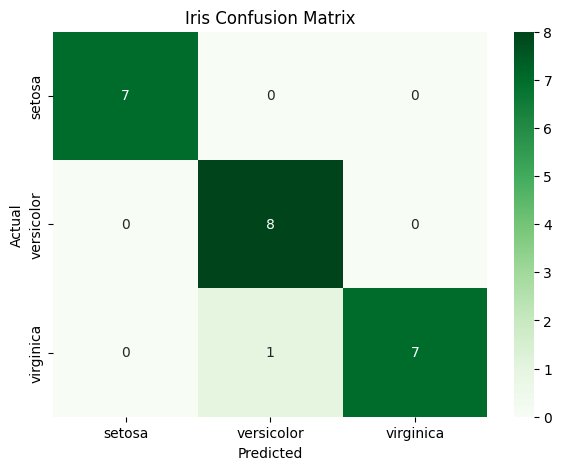

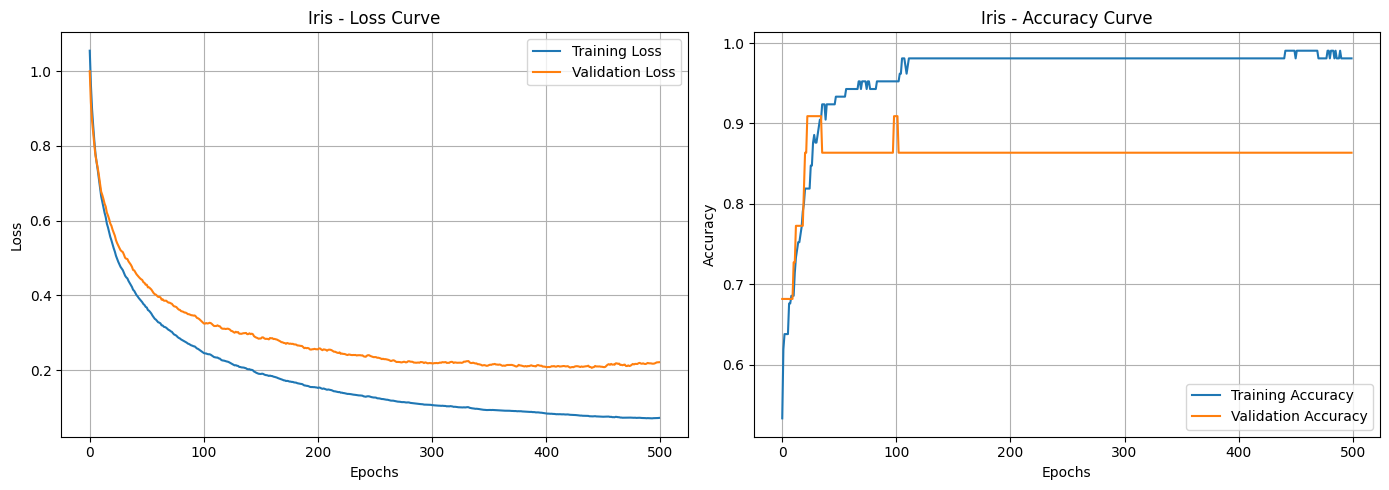


New Flower Prediction:
setosa

IRIS PROJECT COMPLETED!


In [3]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)

data = load_iris()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print("Features:", data.feature_names)
print("Classes:", data.target_names)

print("\nDataset Preview:")

print(pd.DataFrame(
    X,
    columns=data.feature_names
).head())

print("\nClass Distribution:")

print(pd.Series(y).value_counts())


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)



scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


# ============================================================
#  ONE-HOT ENCODING
# ============================================================

num_classes = 3

y_train = np.eye(num_classes)[y_train]
y_val = np.eye(num_classes)[y_val]

# Keep original integer labels for evaluation
y_test_labels = y_test.copy()

y_test = np.eye(num_classes)[y_test]

print("\nTraining Shape:", X_train.shape)
print("One-Hot Target Shape:", y_train.shape)
print("Testing Shape:", X_test.shape)


# ============================================================
# BUILD NEURAL NETWORK FROM SCRATCH
# ============================================================

class NeuralNetwork:

    def __init__(
        self,
        input_size,
        hidden1=16,
        hidden2=8,
        output_size=3,
        learning_rate=0.01,
        epochs=500,
        batch_size=16,
        dropout_rate=0.20,
        l2_lambda=0.001
    ):

        self.output_size = output_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.dropout_rate = dropout_rate
        self.l2_lambda = l2_lambda

        # Initialize weights and biases

        self.W1 = np.random.randn(input_size, hidden1) * np.sqrt(2 / input_size)
        self.b1 = np.zeros((1, hidden1))

        self.W2 = np.random.randn(hidden1, hidden2) * np.sqrt(2 / hidden1)
        self.b2 = np.zeros((1, hidden2))

        self.W3 = np.random.randn(hidden2, output_size) * np.sqrt(2 / hidden2)
        self.b3 = np.zeros((1, output_size))

        # Training history

        self.train_losses = []
        self.val_losses = []

        self.train_accuracies = []
        self.val_accuracies = []


    # Activation functions

    def relu(self, z):
        return np.maximum(0, z)

    def relu_derivative(self, z):
        return (z > 0).astype(float)

    def softmax(self, z):

        z = z - np.max(z, axis=1, keepdims=True)

        exp_values = np.exp(z)

        return exp_values / np.sum(
            exp_values,
            axis=1,
            keepdims=True
        )


    # Forward propagation

    def forward(self, X, training=False):

        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.relu(self.Z1)

        # Dropout layer 1

        if training and self.dropout_rate > 0:

            self.D1 = (
                np.random.rand(*self.A1.shape) >= self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.A1 *= self.D1

        else:
            self.D1 = np.ones_like(self.A1)


        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self.relu(self.Z2)

        # Dropout layer 2

        if training and self.dropout_rate > 0:

            self.D2 = (
                np.random.rand(*self.A2.shape) >= self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.A2 *= self.D2

        else:
            self.D2 = np.ones_like(self.A2)


        self.Z3 = self.A2 @ self.W3 + self.b3

        # Softmax output

        self.A3 = self.softmax(self.Z3)

        return self.A3


    # Categorical Cross-Entropy + L2

    def calculate_loss(self, y_true, y_pred):

        eps = 1e-9
        m = len(y_true)

        cce = -np.mean(
            np.sum(
                y_true * np.log(y_pred + eps),
                axis=1
            )
        )

        l2 = (self.l2_lambda / (2 * m)) * (
            np.sum(self.W1 ** 2) +
            np.sum(self.W2 ** 2) +
            np.sum(self.W3 ** 2)
        )

        return cce + l2


    # Backpropagation

    def backward(self, X, y):

        m = X.shape[0]

        # Output layer

        dZ3 = self.A3 - y

        dW3 = self.A2.T @ dZ3 / m
        db3 = np.sum(dZ3, axis=0, keepdims=True) / m

        # Hidden layer 2

        dA2 = dZ3 @ self.W3.T
        dA2 *= self.D2

        dZ2 = dA2 * self.relu_derivative(self.Z2)

        dW2 = self.A1.T @ dZ2 / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        # Hidden layer 1

        dA1 = dZ2 @ self.W2.T
        dA1 *= self.D1

        dZ1 = dA1 * self.relu_derivative(self.Z1)

        dW1 = X.T @ dZ1 / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        # L2 regularization gradients

        dW1 += self.l2_lambda * self.W1 / m
        dW2 += self.l2_lambda * self.W2 / m
        dW3 += self.l2_lambda * self.W3 / m

        return dW1, db1, dW2, db2, dW3, db3


    # Gradient Descent

    def update_weights(self, gradients):

        dW1, db1, dW2, db2, dW3, db3 = gradients

        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1

        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2

        self.W3 -= self.learning_rate * dW3
        self.b3 -= self.learning_rate * db3


    # Prediction

    def predict(self, X):

        probabilities = self.forward(X, training=False)

        return np.argmax(probabilities, axis=1)


    # Accuracy

    def accuracy(self, X, y):

        predictions = self.predict(X)

        actual = np.argmax(y, axis=1)

        return np.mean(predictions == actual)


    # Training

    def fit(self, X_train, y_train, X_val, y_val):

        n = X_train.shape[0]

        for epoch in range(self.epochs):

            indices = np.random.permutation(n)

            X_shuffled = X_train[indices]
            y_shuffled = y_train[indices]

            # Mini-batch Gradient Descent

            for start in range(0, n, self.batch_size):

                end = start + self.batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                self.forward(X_batch, training=True)

                gradients = self.backward(X_batch, y_batch)

                self.update_weights(gradients)


            # Calculate training and validation losses

            train_pred = self.forward(X_train)
            val_pred = self.forward(X_val)

            train_loss = self.calculate_loss(y_train, train_pred)
            val_loss = self.calculate_loss(y_val, val_pred)

            train_acc = self.accuracy(X_train, y_train)
            val_acc = self.accuracy(X_val, y_val)

            self.train_losses.append(train_loss)
            self.val_losses.append(val_loss)

            self.train_accuracies.append(train_acc)
            self.val_accuracies.append(val_acc)


            if (epoch + 1) % 50 == 0:

                print(
                    f"Epoch {epoch+1}/{self.epochs} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Val Loss: {val_loss:.4f} | "
                    f"Train Accuracy: {train_acc:.4f} | "
                    f"Val Accuracy: {val_acc:.4f}"
                )


    # Visualize performance

    def plot_history(self):

        plt.figure(figsize=(14, 5))

        plt.subplot(1, 2, 1)

        plt.plot(self.train_losses, label="Training Loss")
        plt.plot(self.val_losses, label="Validation Loss")

        plt.title("Iris - Loss Curve")
        plt.xlabel("Epochs")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid()

        plt.subplot(1, 2, 2)

        plt.plot(self.train_accuracies, label="Training Accuracy")
        plt.plot(self.val_accuracies, label="Validation Accuracy")

        plt.title("Iris - Accuracy Curve")
        plt.xlabel("Epochs")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid()

        plt.tight_layout()
        plt.show()


# ============================================================
#  CREATE AND TRAIN MLP
# ============================================================

model = NeuralNetwork(

    input_size=X_train.shape[1],

    hidden1=16,

    hidden2=8,

    output_size=3,

    learning_rate=0.01,

    epochs=500,

    batch_size=16,

    dropout_rate=0.20,

    l2_lambda=0.001
)

model.fit(X_train, y_train, X_val, y_val)


# ============================================================
#  MODEL EVALUATION
# ============================================================

y_pred = model.predict(X_test)

y_actual = y_test_labels

print("\nIRIS MODEL RESULTS")

print("Accuracy:", accuracy_score(y_actual, y_pred))

print("Precision:", precision_score(
    y_actual, y_pred, average="weighted"
))

print("Recall:", recall_score(
    y_actual, y_pred, average="weighted"
))

print("F1 Score:", f1_score(
    y_actual, y_pred, average="weighted"
))

print("\nClassification Report:")

print(
    classification_report(
        y_actual,
        y_pred,
        target_names=data.target_names
    )
)


cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Iris Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



model.plot_history()


# ============================================================
#  PREDICT A NEW FLOWER
# ============================================================

new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

new_flower = scaler.transform(new_flower)

prediction = model.predict(new_flower)

print("\nNew Flower Prediction:")

print(data.target_names[prediction[0]])


print("\nIRIS PROJECT COMPLETED!")



#==================================================
# PROJECT 3: TITANIC BINARY CLASSIFICATION
 (NEURAL NETWORK FROM SCRATCH USING NUMPY)
#==================================================


Dataset Shape: (891, 15)

Dataset Preview:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class  

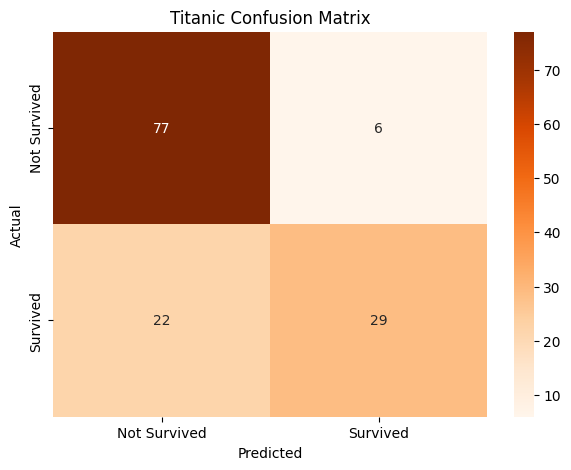

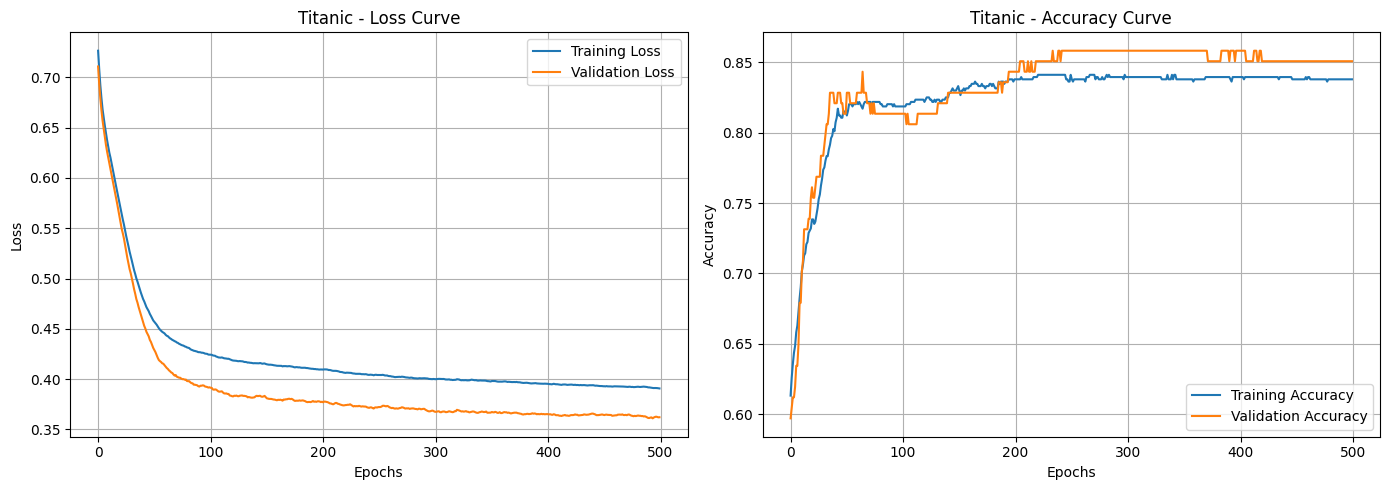


New Passenger Prediction:
Passenger Survived

TITANIC PROJECT COMPLETED!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [5]:



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)


df = sns.load_dataset("titanic")

print("Dataset Shape:", df.shape)

print("\nDataset Preview:")

print(df.head())

print("\nMissing Values:")

print(df.isnull().sum())


features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features].copy()

y = df["survived"].values.reshape(-1, 1)

print("\nSelected Features:")

print(X.head())



X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


#  HANDLE MISSING VALUES


# Calculate medians from training data only

age_median = X_train["age"].median()

fare_median = X_train["fare"].median()

# Calculate mode from training data only

embarked_mode = X_train["embarked"].mode()[0]


def preprocess_titanic(data):

    data = data.copy()

    # Numerical missing values

    data["age"] = data["age"].fillna(age_median)

    data["fare"] = data["fare"].fillna(fare_median)

    # Categorical missing values

    data["embarked"] = data["embarked"].fillna(
        embarked_mode
    )


    data["sex"] = data["sex"].map({
        "male": 0,
        "female": 1
    })

    # One-hot encoding for embarked

    data = pd.get_dummies(
        data,
        columns=["embarked"],
        dtype=int
    )

    # Ensure consistent columns

    expected_columns = [
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked_C",
        "embarked_Q",
        "embarked_S"
    ]

    data = data.reindex(
        columns=expected_columns,
        fill_value=0
    )

    return data


X_train = preprocess_titanic(X_train)

X_val = preprocess_titanic(X_val)

X_test = preprocess_titanic(X_test)


print("\nProcessed Training Data:")

print(X_train.head())

print("\nMissing Values After Preprocessing:")

print(X_train.isnull().sum().sum())


# ============================================================
# CONVERT DATA INTO NUMPY ARRAYS
# ============================================================

X_train = X_train.values.astype(float)

X_val = X_val.values.astype(float)

X_test = X_test.values.astype(float)


scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)


print("\nTraining Shape:", X_train.shape)

print("Validation Shape:", X_val.shape)

print("Testing Shape:", X_test.shape)



class NeuralNetwork:

    def __init__(
        self,
        input_size,
        hidden1=16,
        hidden2=8,
        output_size=1,
        learning_rate=0.01,
        epochs=500,
        batch_size=32,
        dropout_rate=0.20,
        l2_lambda=0.001
    ):

        self.output_size = output_size

        self.learning_rate = learning_rate

        self.epochs = epochs

        self.batch_size = batch_size

        self.dropout_rate = dropout_rate

        self.l2_lambda = l2_lambda

        # Initialize weights and biases

        self.W1 = np.random.randn(
            input_size, hidden1
        ) * np.sqrt(2 / input_size)

        self.b1 = np.zeros((1, hidden1))

        self.W2 = np.random.randn(
            hidden1, hidden2
        ) * np.sqrt(2 / hidden1)

        self.b2 = np.zeros((1, hidden2))

        self.W3 = np.random.randn(
            hidden2, output_size
        ) * np.sqrt(2 / hidden2)

        self.b3 = np.zeros((1, output_size))

        # Store training history

        self.train_losses = []

        self.val_losses = []

        self.train_accuracies = []

        self.val_accuracies = []


    # Activation functions

    def relu(self, z):

        return np.maximum(0, z)


    def relu_derivative(self, z):

        return (z > 0).astype(float)


    def sigmoid(self, z):

        z = np.clip(z, -500, 500)

        return 1 / (1 + np.exp(-z))


    # Forward propagation

    def forward(self, X, training=False):

        self.Z1 = X @ self.W1 + self.b1

        self.A1 = self.relu(self.Z1)

        # Dropout layer 1

        if training and self.dropout_rate > 0:

            self.D1 = (
                np.random.rand(*self.A1.shape)
                >= self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.A1 *= self.D1

        else:

            self.D1 = np.ones_like(self.A1)


        self.Z2 = self.A1 @ self.W2 + self.b2

        self.A2 = self.relu(self.Z2)

        # Dropout layer 2

        if training and self.dropout_rate > 0:

            self.D2 = (
                np.random.rand(*self.A2.shape)
                >= self.dropout_rate
            ) / (1 - self.dropout_rate)

            self.A2 *= self.D2

        else:

            self.D2 = np.ones_like(self.A2)


        self.Z3 = self.A2 @ self.W3 + self.b3

        self.A3 = self.sigmoid(self.Z3)

        return self.A3


    # Binary Cross-Entropy + L2 Regularization

    def calculate_loss(self, y_true, y_pred):

        eps = 1e-9

        m = len(y_true)

        bce = -np.mean(
            y_true * np.log(y_pred + eps) +
            (1 - y_true) * np.log(1 - y_pred + eps)
        )

        l2 = (self.l2_lambda / (2 * m)) * (
            np.sum(self.W1 ** 2) +
            np.sum(self.W2 ** 2) +
            np.sum(self.W3 ** 2)
        )

        return bce + l2


    # Backpropagation

    def backward(self, X, y):

        m = X.shape[0]

        # Output layer

        dZ3 = self.A3 - y

        dW3 = self.A2.T @ dZ3 / m

        db3 = np.sum(
            dZ3,
            axis=0,
            keepdims=True
        ) / m


        # Hidden layer 2

        dA2 = dZ3 @ self.W3.T

        dA2 *= self.D2

        dZ2 = dA2 * self.relu_derivative(self.Z2)

        dW2 = self.A1.T @ dZ2 / m

        db2 = np.sum(
            dZ2,
            axis=0,
            keepdims=True
        ) / m


        # Hidden layer 1

        dA1 = dZ2 @ self.W2.T

        dA1 *= self.D1

        dZ1 = dA1 * self.relu_derivative(self.Z1)

        dW1 = X.T @ dZ1 / m

        db1 = np.sum(
            dZ1,
            axis=0,
            keepdims=True
        ) / m


        # L2 regularization gradients

        dW1 += self.l2_lambda * self.W1 / m

        dW2 += self.l2_lambda * self.W2 / m

        dW3 += self.l2_lambda * self.W3 / m


        return dW1, db1, dW2, db2, dW3, db3


    # Update weights using Gradient Descent

    def update_weights(self, gradients):

        dW1, db1, dW2, db2, dW3, db3 = gradients

        self.W1 -= self.learning_rate * dW1

        self.b1 -= self.learning_rate * db1

        self.W2 -= self.learning_rate * dW2

        self.b2 -= self.learning_rate * db2

        self.W3 -= self.learning_rate * dW3

        self.b3 -= self.learning_rate * db3


    # Prediction

    def predict(self, X):

        probabilities = self.forward(
            X,
            training=False
        )

        return (probabilities >= 0.5).astype(int).ravel()


    # Accuracy

    def accuracy(self, X, y):

        predictions = self.predict(X)

        return np.mean(predictions == y.ravel())


    # Training

    def fit(self, X_train, y_train, X_val, y_val):

        n = X_train.shape[0]

        for epoch in range(self.epochs):

            indices = np.random.permutation(n)

            X_shuffled = X_train[indices]

            y_shuffled = y_train[indices]


            # Mini-batch Gradient Descent

            for start in range(0, n, self.batch_size):

                end = start + self.batch_size

                X_batch = X_shuffled[start:end]

                y_batch = y_shuffled[start:end]


                self.forward(
                    X_batch,
                    training=True
                )

                gradients = self.backward(
                    X_batch,
                    y_batch
                )

                self.update_weights(gradients)


            # Training and validation loss

            train_pred = self.forward(X_train)

            val_pred = self.forward(X_val)

            train_loss = self.calculate_loss(
                y_train,
                train_pred
            )

            val_loss = self.calculate_loss(
                y_val,
                val_pred
            )


            # Accuracy

            train_acc = self.accuracy(
                X_train,
                y_train
            )

            val_acc = self.accuracy(
                X_val,
                y_val
            )


            self.train_losses.append(train_loss)

            self.val_losses.append(val_loss)

            self.train_accuracies.append(train_acc)

            self.val_accuracies.append(val_acc)


            if (epoch + 1) % 50 == 0:

                print(
                    f"Epoch {epoch+1}/{self.epochs} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Val Loss: {val_loss:.4f} | "
                    f"Train Accuracy: {train_acc:.4f} | "
                    f"Val Accuracy: {val_acc:.4f}"
                )


    # Visualize performance

    def plot_history(self):

        plt.figure(figsize=(14, 5))

        # Loss curve

        plt.subplot(1, 2, 1)

        plt.plot(
            self.train_losses,
            label="Training Loss"
        )

        plt.plot(
            self.val_losses,
            label="Validation Loss"
        )

        plt.title("Titanic - Loss Curve")

        plt.xlabel("Epochs")

        plt.ylabel("Loss")

        plt.legend()

        plt.grid()


        # Accuracy curve

        plt.subplot(1, 2, 2)

        plt.plot(
            self.train_accuracies,
            label="Training Accuracy"
        )

        plt.plot(
            self.val_accuracies,
            label="Validation Accuracy"
        )

        plt.title("Titanic - Accuracy Curve")

        plt.xlabel("Epochs")

        plt.ylabel("Accuracy")

        plt.legend()

        plt.grid()

        plt.tight_layout()

        plt.show()


# ============================================================
# CREATE AND TRAIN MLP MODEL
# ============================================================

model = NeuralNetwork(

    input_size=X_train.shape[1],

    hidden1=16,

    hidden2=8,

    output_size=1,

    learning_rate=0.01,

    epochs=500,

    batch_size=32,

    dropout_rate=0.20,

    l2_lambda=0.001
)

model.fit(
    X_train,
    y_train,
    X_val,
    y_val
)




y_pred = model.predict(X_test)

y_actual = y_test.ravel()

print("\nTITANIC MODEL RESULTS")

print("Accuracy:", accuracy_score(y_actual, y_pred))

print("Precision:", precision_score(y_actual, y_pred))

print("Recall:", recall_score(y_actual, y_pred))

print("F1 Score:", f1_score(y_actual, y_pred))

print("\nClassification Report:")

print(
    classification_report(
        y_actual,
        y_pred,
        target_names=["Not Survived", "Survived"]
    )
)



cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Titanic Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()




model.plot_history()


# ============================================================
#  PREDICT A NEW PASSENGER
# ============================================================

# Feature order:
# pclass, sex, age, sibsp, parch, fare,
# embarked_C, embarked_Q, embarked_S

new_passenger = pd.DataFrame(
    [[1, 1, 25, 0, 0, 80, 1, 0, 0]],
    columns=[
        "pclass",
        "sex",
        "age",
        "sibsp",
        "parch",
        "fare",
        "embarked_C",
        "embarked_Q",
        "embarked_S"
    ]
)

new_passenger = scaler.transform(
    new_passenger
)

prediction = model.predict(new_passenger)

print("\nNew Passenger Prediction:")

if prediction[0] == 1:

    print("Passenger Survived")

else:

    print("Passenger Did Not Survive")


print("\nTITANIC PROJECT COMPLETED!")
